# Pytorch Prequisites before ARENA

## Tensor puzzles first from [srush/Tensor-Puzzles](https://github.com/srush/Tensor-Puzzles)

In [1]:
from lib import draw_examples, make_test, run_test
import torch
from torch import Tensor
import numpy as np
import jaxtyping
from jaxtyping import Float

tensor = torch.tensor
tensor

<function torch._VariableFunctionsClass.tensor>

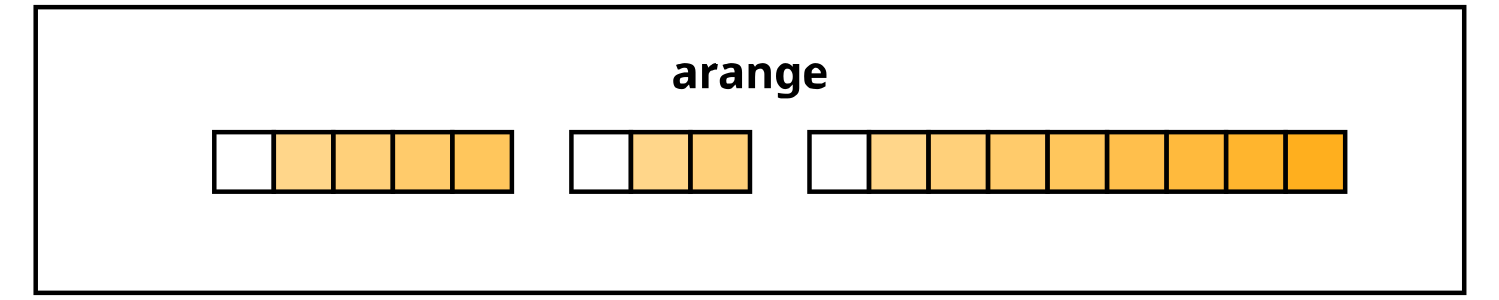

In [2]:
def arange(i: int):
    "Use this function to replace a for-loop."
    return torch.tensor(range(i))

draw_examples("arange", [{"" : arange(i)} for i in [5, 3, 9]])

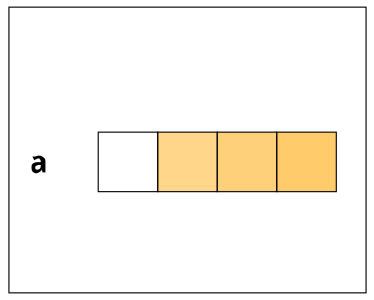

In [3]:
# broadcasting examples

draw_examples("", [{"a": (arange(4))}])

So what is Tensor Broadcasting here?

In simple terms, its the operation where the size of a smaller tensor is expanded to fit the size of a larger tensor during element-wise operations without copying data in memory.

The rules for broadcasting:
*   two dimensions are compatible if they have the exact same length
*   a dimension of length $1$ can stretch to match the corresponding dimension of the other tensor
*   if one tensor has fewer dimensions, its shape is treated as padded with $1s$ on the left until both have the same number of dimensions

In [4]:
torch.arange(10), np.arange(10) # one dimension tensors

(tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]))

In [5]:
t1 = np.arange(7)
t2 = np.arange(3)
out = [t1, t2, t1+t2]

draw_examples("", [{f"tensor {t}": t} for t in out])

ValueError: operands could not be broadcast together with shapes (7,) (3,) 

In [6]:
t1.shape, t2.shape

((7,), (3,))

above, i have tried to perform element-wise addition on two tensors of sizes (7,) and (3,), which is not possible because both of them have to be equal to $1$, or one of them IS $1$. 

A quick fix would be to add a new axis to one of the tensors, converting it from a 1d to a 2d tensor.

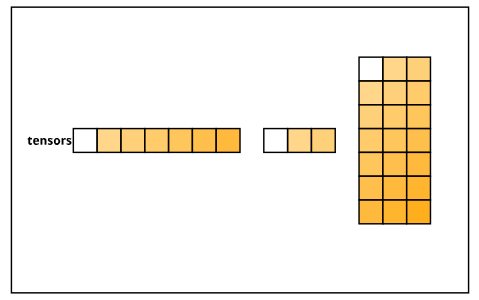

In [7]:
draw_examples("", [{"tensors": t} for t in [t1, t2, t1[:, None] + t2]])

Notice the shape above, its no longer a `1d` tensor when you added `t1` of shape `(7,1)` and `t2` of shape `(3,)` together. 

One of the rules of broadcasting is that either both the tensors are of same dimension, or one of them is $1$. Since adding an axis to `t1` changed its dimensions, and broadcasting aligns dimensions from the rightmost trailing dimension (aligns from the right, not left), `t2` is treated as `(1,3)` and padded along its row dimensions to become `(1,3)`.

In [8]:
s1 = 4
t1 + s1 # element-wise addition (tensor + scalar)

array([ 4,  5,  6,  7,  8,  9, 10])

In [9]:
t3 = torch.arange(4)
t4 = torch.tensor([4])
t3 + t4 # automatically broadcasted

tensor([4, 5, 6, 7])

In [10]:
t5 = torch.arange(5)
t6 = torch.arange(10)
t5 + t6 # wont get automatically broadcasted

RuntimeError: The size of tensor a (5) must match the size of tensor b (10) at non-singleton dimension 0

In [11]:
t5[:, None] + t6

tensor([[ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9],
        [ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10],
        [ 2,  3,  4,  5,  6,  7,  8,  9, 10, 11],
        [ 3,  4,  5,  6,  7,  8,  9, 10, 11, 12],
        [ 4,  5,  6,  7,  8,  9, 10, 11, 12, 13]])

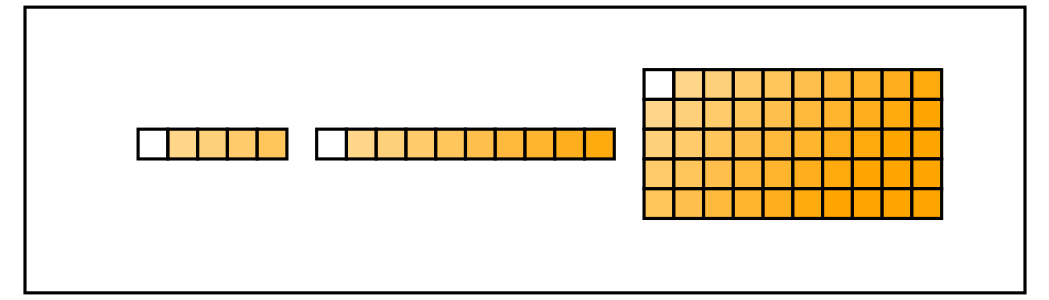

In [12]:
draw_examples("", [{"": t} for t in [t5, t6, t5[:, None]+t6]])

In [13]:
print(f"t5: {t5.shape}")
print(f"t6: {t6.shape}")
print(f"t5+t6: {torch.tensor(t5[:, None]+t6).shape}")

t5: torch.Size([5])
t6: torch.Size([10])
t5+t6: torch.Size([5, 10])


/var/folders/z1/cd374qgx421_hlkd_bg_nxtr0000gn/T/ipykernel_78036/3335058600.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  print(f"t5+t6: {torch.tensor(t5[:, None]+t6).shape}")


In [14]:
sc = torch.tensor([[5], [10]])
t6 + sc, sc.shape, torch.tensor(t6+sc).shape

/var/folders/z1/cd374qgx421_hlkd_bg_nxtr0000gn/T/ipykernel_78036/782724692.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t6 + sc, sc.shape, torch.tensor(t6+sc).shape


(tensor([[ 5,  6,  7,  8,  9, 10, 11, 12, 13, 14],
         [10, 11, 12, 13, 14, 15, 16, 17, 18, 19]]),
 torch.Size([2, 1]),
 torch.Size([2, 10]))

the two tensors inside `sc` are added separately to `t6`, therefore giving an output tensor of shape `[2, 10]`

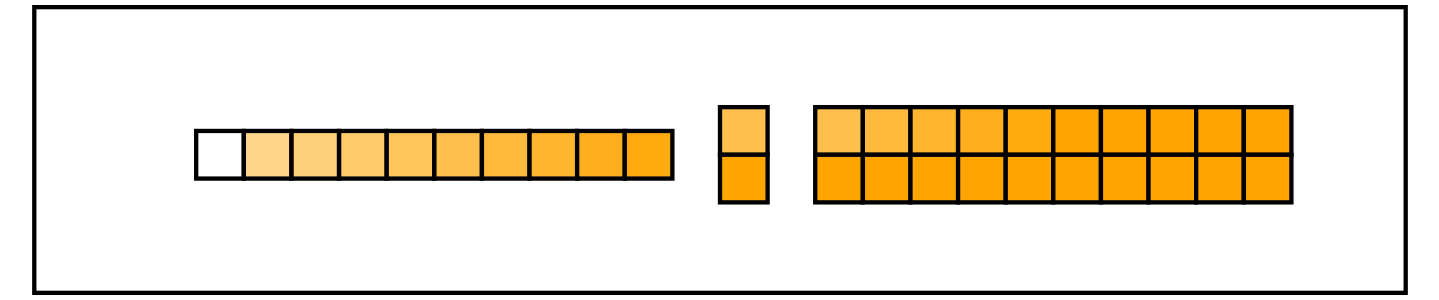

In [15]:
draw_examples("", [{"": t} for t in [t6, sc, t6+sc]])

In [16]:
broadcasted_tensors = torch.broadcast_tensors(t6, sc)
print(f"Shape of t6 after broadcasting: {broadcasted_tensors[0].shape}")
print(f"Shape of sc after broadcasting: {broadcasted_tensors[1].shape}")

Shape of t6 after broadcasting: torch.Size([2, 10])
Shape of sc after broadcasting: torch.Size([2, 10])


In [17]:
print(broadcasted_tensors[0])
print(broadcasted_tensors[1])

tensor([[0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
        [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]])
tensor([[ 5,  5,  5,  5,  5,  5,  5,  5,  5,  5],
        [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]])


now instead of taking [[5], [10]] and adding them separately to two copies of `t6`, the function has produced two broadcasted tensors ready to use

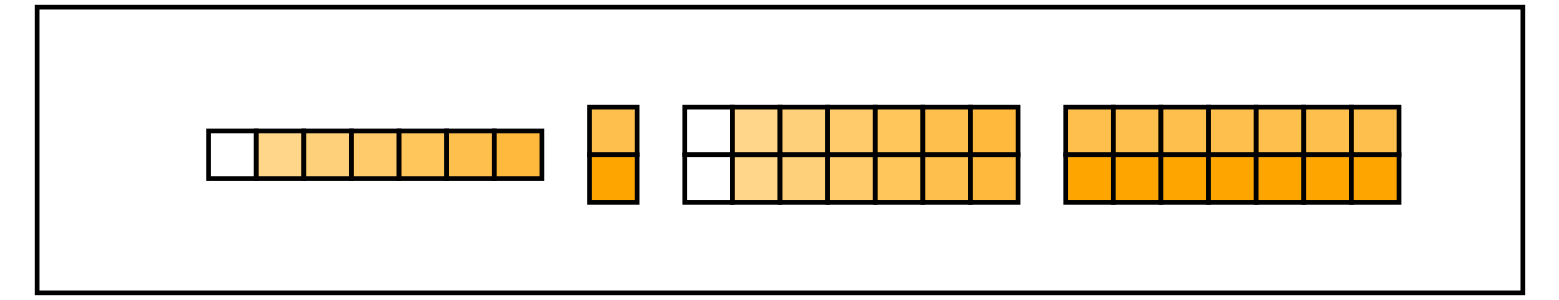

In [18]:
a = torch.arange(7)
b = torch.tensor([[5], [10]])
a_b, b_b = torch.broadcast_tensors(a, b)

draw_examples("", [{"": t} for t in [a, b, a_b, b_b]])

## Puzzle 1 - ones
Compute ones - the vector of all ones

Return a new array of given shape and type, filled with ones.

In [25]:
def ones_spec(out):
    for i in range(len(out)):
        out[i] = 1
    
def ones(i: int) -> Float[Tensor, "{i}"]:
    tensor = np.arange(i)
    ones_spec(tensor) # modifies the tensor in place
    return tensor

In [26]:
ones(10), ones(10).shape

(array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1]), (10,))

## Puzzle 2 - sum

Compute the sum of a vector

Sum of array elements over a given axis.

In [27]:
def sum_spec(a, out):
    out[0] = 0
    for i in range(len(a)):
        out[0] += a[i]

def sum(a: Float[Tensor, "i"]) -> Float[Tensor, "1"]:
    # out = np.zeros(1, np.float32)
    out = torch.zeros(1)
    print(f"Shape of a: {a.shape}")
    print(f"Shape of out: {out.shape}")
    sum_spec(a, out[:, None]) # broadcast out along the a
    return out


In [28]:
t = torch.rand(6)
sum(t), t.shape, sum(t).shape

Shape of a: torch.Size([6])
Shape of out: torch.Size([1])
Shape of a: torch.Size([6])
Shape of out: torch.Size([1])


(tensor([3.5569]), torch.Size([6]), torch.Size([1]))

## Puzzle 3 - outer

Compute the outer product of two vectors

The outer product of an $m$-dimensional column vector $\mathbf{u}$ and an $n$-dimensional column vector $\mathbf{v}$ is an $m \times n$ matrix denoted by $\mathbf{u} \otimes \mathbf{v}$ or $\mathbf{u}\mathbf{v}^T$ (or $\mathbf{u}\mathbf{v}^\dagger$ for complex vectors), where each entry $(i, j)$ is $u_{i}v_{j}$.

In [29]:
def outer_spec(a, b, out):
    for i in range(len(out)):
        for j in range(len(out[0])):
            out[i][j] = a[i] * b[j]

def outer(a: Float[Tensor, "i"], b: Float[Tensor, "j"]) -> Float[Tensor, "i j"]:
    out = torch.zeros((len(a), len(b))) # it will have len(a) rows and len(b) columns
    outer_spec(a, b, out[:, None])
    return out

In [30]:
a = torch.rand(4)
b = torch.rand(7)
outer(a, b)

tensor([[0.0704, 0.0704, 0.0704, 0.0704, 0.0704, 0.0704, 0.0704],
        [0.3091, 0.3091, 0.3091, 0.3091, 0.3091, 0.3091, 0.3091],
        [0.7433, 0.7433, 0.7433, 0.7433, 0.7433, 0.7433, 0.7433],
        [0.3587, 0.3587, 0.3587, 0.3587, 0.3587, 0.3587, 0.3587]])

## Puzzle 4 - diag

Compute the diagonal vector of a square matrix

Extract a diagonal or construct a diagonal array.

In [31]:
def diag_spec(a, out):
    for i in range(len(a)):
        out[i] = a[i][i]

def diag(a: Float[Tensor, "i i"]) -> Float[Tensor, "i"]:
    out = torch.zeros(len(a))
    diag_spec(a, out)
    return out

In [32]:
mat = torch.rand((3,3))
print(mat)

for i in range(len(mat)):
    print(mat[i][i])

diag(mat)

tensor([[0.4332, 0.1451, 0.5172],
        [0.4600, 0.7092, 0.5127],
        [0.6790, 0.0406, 0.6225]])
tensor(0.4332)
tensor(0.7092)
tensor(0.6225)


tensor([0.4332, 0.7092, 0.6225])

## Puzzle 5 - eye

Compute the identity matrix

Return a 2-D array with ones on the diagonal and zeros elsewhere.

In [33]:
def eye_spec(out):
    for i in range(len(out)):
        out[i][i] = 1

def eye(j: int) -> Float[Tensor, "j j"]:
    out = torch.zeros((j, j))
    eye_spec(out)
    return out

In [34]:
mat = torch.zeros((4, 4))

for i in range(len(mat)):
    mat[i][i] = 1

print(mat)
print()
eye(4), mat == eye(4)

tensor([[1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [0., 0., 1., 0.],
        [0., 0., 0., 1.]])



(tensor([[1., 0., 0., 0.],
         [0., 1., 0., 0.],
         [0., 0., 1., 0.],
         [0., 0., 0., 1.]]),
 tensor([[True, True, True, True],
         [True, True, True, True],
         [True, True, True, True],
         [True, True, True, True]]))

## Puzzle 6 - triu

Compute the upper triangular matrix

Upper triangle of an array.

In [35]:
def triu_spec(out):
    for i in range(len(out)):
        for j in range(len(out)):
            if i <= j:
                continue
            else:
                out[i][j] = 0

def triu(j: int) -> Float[Tensor, "j j"]:
    out = torch.ones((j, j))
    triu_spec(out)
    return out

In [36]:
mat = torch.rand((4,4))

for i in range(len(mat)):
    for j in range(len(mat)):
        if i <= j:
            continue
        else:
            mat[i][j] = 0

mat, triu(4)

(tensor([[0.5275, 0.9024, 0.5934, 0.4451],
         [0.0000, 0.7073, 0.4081, 0.0567],
         [0.0000, 0.0000, 0.2985, 0.1896],
         [0.0000, 0.0000, 0.0000, 0.2493]]),
 tensor([[1., 1., 1., 1.],
         [0., 1., 1., 1.],
         [0., 0., 1., 1.],
         [0., 0., 0., 1.]]))

## Puzzle 7 - cumsum

Compute the cumulative sum

Return the cumulative sum of the elements along a given axis.

In [37]:
def cumsum_spec(a, out):
    total = 0
    for i in range(len(a)):
        out[i] = total + a[i]
        total += a[i]

def cumsum(a: Float[Tensor, "i"]) -> Float[Tensor, "i"]:
    out = torch.zeros_like(a)
    cumsum_spec(a, out)
    return out

In [38]:
x = torch.randint(10, (5,))
sum, out = 0, torch.zeros_like(x)

for i in range(len(x)):
    out[i] = sum + x[i]
    sum += x[i]

x, out, cumsum(x)

(tensor([6, 8, 2, 2, 5]),
 tensor([ 6, 14, 16, 18, 23]),
 tensor([ 6, 14, 16, 18, 23]))

## Puzzle 8 - diff

Compute the running difference

Calculate the n-th discrete difference along the given axis.

In [39]:
def diff_spec(a, out):
    out[0] = a[0]
    for i in range(1, len(out)):
        out[i] = a[i] - a[i-1]

def diff(a: Float[Tensor, "i"], i: int) -> Float[Tensor, "i"]:
    out = torch.zeros_like(a)
    diff_spec(a, out)
    return out

In [40]:
a = torch.randint(10, (5,))
x = torch.zeros_like(a)

x[0] = a[0]
for i in range(1, len(a)):
    x[i] = a[i] - a[i-1]

a, x, diff(a, len(a))

(tensor([7, 3, 7, 8, 3]),
 tensor([ 7, -4,  4,  1, -5]),
 tensor([ 7, -4,  4,  1, -5]))

## Puzzle 9 - vstack

Compute the matrix of two vectors

Stack arrays in sequence vertically (row wise).

In [41]:
def vstack_spec(a, b, out):
    for i in range(len(out[0])):
        out[0][i] = a[i]
        out[1][i] = b[i]

def vstack(a: Float[Tensor, "i"], b: Float[Tensor, "i"]) -> Float[Tensor, "2 i"]:
    out = torch.zeros((2, len(a)), dtype=a.dtype)
    vstack_spec(a, b, out)
    return out

In [42]:
a, b = torch.randint(10, (3,)), torch.randint(10, (3,))

out = torch.zeros((2, len(a)), dtype=a.dtype)

for i in range(len(a)):
    out[0][i] = a[i]
    out[1][i] = b[i]

a, b, out, vstack(a, b)

(tensor([7, 8, 8]),
 tensor([3, 3, 0]),
 tensor([[7, 8, 8],
         [3, 3, 0]]),
 tensor([[7, 8, 8],
         [3, 3, 0]]))

## Puzzle 10 - roll

Compute the vector shifted 1 circular position

Elements that roll beyond the last position are re-introduced at the first.

In [43]:
def roll_spec(a, out):
    for i in range(len(out)):
        if i + 1 < len(out):
            out[i] = a[i+1]
        else:
            out[i] = a[i + 1 - len(out)]

def roll(a: Float[Tensor, "n"], i: int) -> Float[Tensor, "n"]:
    out = torch.zeros_like(a)
    roll_spec(a, out)
    return out

In [44]:
x = torch.randint(10, (7,))
x, roll(x, 2)

(tensor([4, 0, 2, 3, 0, 5, 1]), tensor([0, 2, 3, 0, 5, 1, 4]))